In [124]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np


In [100]:
dataset=pd.read_csv("data (1).csv")
dataset.head(2)

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,country
0,2014-05-02 00:00:00,313000.0,3.0,1.5,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,USA
1,2014-05-02 00:00:00,2384000.0,5.0,2.5,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,USA


In [101]:
dataset.isnull().sum().sum()

0

In [102]:
dataset.drop("date",axis=1,inplace=True)


In [103]:
dataset.drop("street",axis=1,inplace=True)


In [104]:
dataset.drop("statezip",axis=1,inplace=True)


In [105]:
dataset.drop("country",axis=1,inplace=True)


In [106]:
dataset.drop("city",axis=1,inplace=True)


In [107]:
dataset.head(3)

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
0,313000.0,3.0,1.5,1340,7912,1.5,0,0,3,1340,0,1955,2005
1,2384000.0,5.0,2.5,3650,9050,2.0,0,4,5,3370,280,1921,0
2,342000.0,3.0,2.0,1930,11947,1.0,0,0,4,1930,0,1966,0


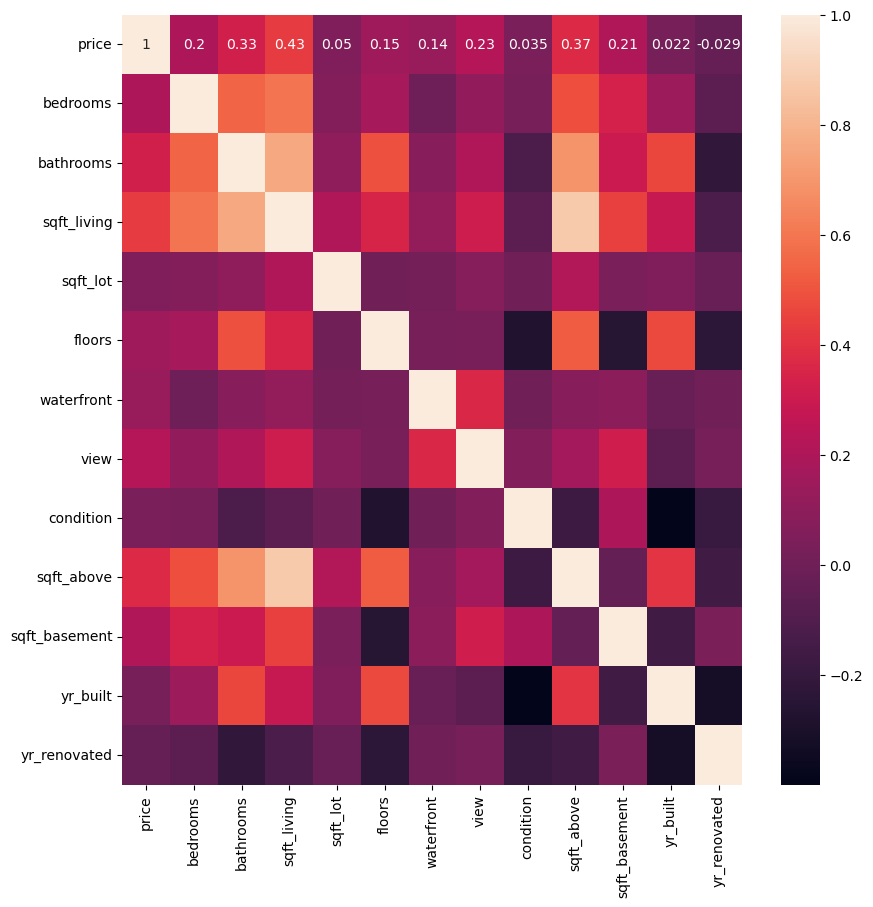

In [108]:
plt.figure(figsize=(10,10))
sns.heatmap(data=dataset.corr(),annot=True)
plt.show()

In [109]:
x=dataset[["bedrooms","bathrooms","sqft_living","sqft_lot","floors","waterfront","view","condition","sqft_above","sqft_basement","yr_built","yr_renovated"]]
y=dataset[["price"]]


In [110]:
from sklearn.preprocessing import StandardScaler

In [111]:
sc=StandardScaler()
x=pd.DataFrame(sc.fit_transform(x),columns=x.columns)
x.head()

,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated
0,-0.441122,-0.843204,-0.829971,-0.193434,-0.022416,-0.085004,-0.309194,-0.667112,-0.565224,-0.672464,-0.531014,1.221670
1,1.759705,0.432802,1.568528,-0.161718,0.906555,-0.085004,4.830079,2.286416,1.789559,-0.069128,-1.674693,-0.825693
2,-0.441122,-0.205201,-0.217367,-0.080978,-0.951388,-0.085004,-0.309194,0.809652,0.119171,-0.672464,-0.161000,-0.825693
3,-0.441122,0.113800,-0.144686,-0.190145,-0.951388,-0.085004,-0.309194,0.809652,-0.959621,1.482306,-0.261913,-0.825693
4,0.659291,0.432802,-0.206984,-0.121306,-0.951388,-0.085004,-0.309194,0.809652,-0.797222,1.051352,0.175376,1.208396


In [112]:
from sklearn.model_selection import train_test_split

In [113]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [114]:
x_test.size,x_train.size

(11040, 44160)

In [125]:
from sklearn.metrics import mean_absolute_error,mean_squared_error


In [115]:
from sklearn.linear_model import LinearRegression,Lasso,Ridge

In [116]:
lr=LinearRegression()
lr.fit(x_train,y_train)

LinearRegression()

In [117]:
lr.score(x_test,y_test)*100

3.228385663277078

In [118]:
lr.coef_

array([[-58612.02450797,  28620.9187631 , 137630.25418366,
        -18457.45554177,  37581.7604078 ,  32277.52943857,
         34834.37139813,  19864.74096026, 120697.0887004 ,
         61415.30012402, -76377.6773788 ,   8089.00372636]])

In [129]:
print(mean_squared_error(y_test,lr.predict(x_test)))
print(mean_absolute_error(y_test,lr.predict(x_test)))
print(np.sqrt(mean_squared_error(y_test,lr.predict(x_test))))

986921767056.1313
210908.17325011524
993439.3625461654


In [119]:
#Lasso

In [120]:
la=Lasso(alpha=0.5)
la.fit(x_train,y_train)
la.score(x_test,y_test)*100

C:\Users\Suchana\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:631: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.068e+13, tolerance: 5.229e+10
  model = cd_fast.enet_coordinate_descent(


3.228361379456879

In [130]:
print(mean_squared_error(y_test,la.predict(x_test)))
print(mean_absolute_error(y_test,la.predict(x_test)))
print(np.sqrt(mean_squared_error(y_test,la.predict(x_test))))

986922014713.7828
210908.23454034503
993439.4871927444


In [121]:
#ridge

In [123]:
ra=Ridge(alpha=0.5)
ra.fit(x_train,y_train)
ra.score(x_test,y_test)*100

3.2289825896381186

In [131]:
print(mean_squared_error(y_test,ra.predict(x_test)))
print(mean_absolute_error(y_test,ra.predict(x_test)))
print(np.sqrt(mean_squared_error(y_test,ra.predict(x_test))))

986915679324.4854
210903.53805744305
993436.2985740381
